# Plot theta vs D_v/D^a for different \beta's

0.5 0.055466059376958976 0.7554660593769591


/home/wmrs@cbsp.nl/codebase/fluctuating_hydro/.venv/lib/python3.10/site-packages/matplotlib/colors.py:2294: RuntimeWarning: invalid value encountered in subtract
  resdat -= vmin


1.0 -0.11672524937550216 0.5832747506244981
2.0 -0.2839940436453335 0.41600595635466664
3.0 -0.3449004649562935 0.3550995350437066
4.0 -0.3675889935931023 0.3324110064068979
5.0 -0.3760123350114133 0.3239876649885869
10.0 -0.3924776508112632 0.3190951273166771
20.0 -0.4031474475572022 0.3190618765096729
Saved: images/critical_surface_theta_Dv.png
Background: rho_A=0.35, rho_B=0.35, rho_0=0.3


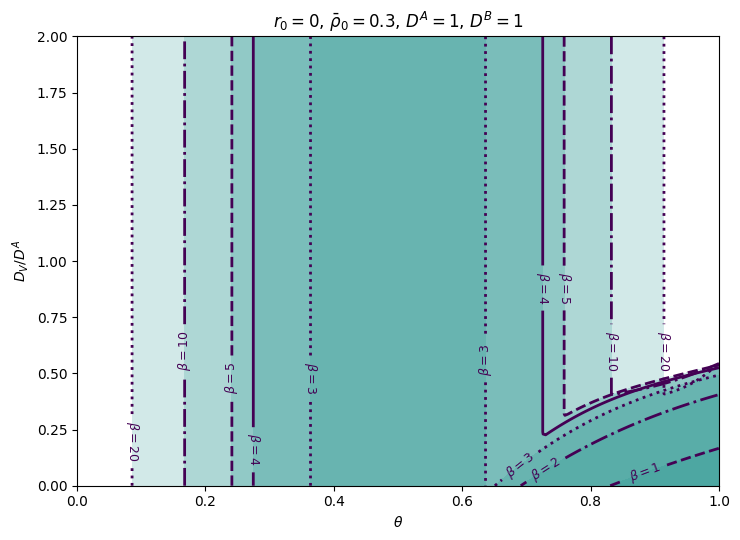

In [5]:
#!/usr/bin/env python3
"""
Tree-level critical surfaces of the Schelling--Voter hydrodynamic theory.

Default example:
    kappa(theta) = [[1-theta, theta],
                    [theta, 1-theta]]
    D_A = D_B = 1
    x axis: theta in [0,1]
    y axis: D_V / D_A
    several beta values shown as separate critical curves.

The script uses the exact microscopic response matrix Theta^{ab}(rho)
and the linear q^2 hydrodynamic matrix J.  The long-wavelength stability
boundary is r0 = min Re eig(J) = 0.  For the stationary Model-B branch one
may instead plot det(J)=0 subject to Tr(J)>0.

Dependencies: numpy, matplotlib.
"""

from dataclasses import dataclass, replace
from math import factorial
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt


# ======================================================================
# USER CONFIGURATION
# ======================================================================

X_PARAM = "theta"
Y_PARAM = "Dv_ratio"

X_RANGE = (0.0, 1.0)
Y_RANGE = (0.0, 2.0)

NX = 201
NY = 201

BETA_VALUES = [0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 10.0, 20.0]

# "r0"         : min Re eig(J) = 0
# "stationary" : det(J) = 0, only where Tr(J) > 0
CRITERION = "r0"

# Baseline parameters. Parameters selected as X_PARAM or Y_PARAM are
# overwritten by the scan.
FIXED = {
    "D_A": 1.0,
    "D_B": 1.0,
    "Dv_ratio": 0.5,
    "beta": 1.0,
    "theta": 0.5,
    "rho_0": 0.30,
    "rho_A": 0.35,
    "rho_B": 0.35,
}

# If True, use rho_A=rho_B=(1-rho_0)/2.
# If False, use FIXED["rho_A"] and FIXED["rho_B"].
SYMMETRIC_BACKGROUND = True

OUTPUT_FILE = "images/critical_surface_theta_Dv.png"
SHOW_FIGURE = False


# ======================================================================
# MODEL
# ======================================================================

@dataclass
class Params:
    D_A: float
    D_B: float
    D_V: float
    beta: float
    theta: float
    rho_A: float
    rho_B: float

    @property
    def rho_0(self):
        return 1.0 - self.rho_A - self.rho_B


def kappa_from_theta(theta):
    """Requested reciprocal one-parameter interaction matrix."""
    return np.array([
        [theta, 1.0-theta],
        [1.0-theta, theta],
    ], dtype=float)


def multinomial3(n, i, j):
    k = n - i - j
    if min(i, j, k) < 0:
        return 0
    return factorial(n) // (factorial(i)*factorial(j)*factorial(k))


def theta_matrix(beta, kappa, rho_A, rho_B):
    r"""Exact finite-spectator response matrix Theta^{ab}(rho).

    Theta^{ab} = < tanh[beta/2 (kappa^{ab}+Delta)]
                   - tanh[beta/2 Delta] >,

    Delta=(m_A-n_A)kappa^{aA}+(m_B-n_B)kappa^{aB},
    with two destination-side and three source-side spectators.
    """
    rho_0 = 1.0 - rho_A - rho_B
    if rho_A < 0 or rho_B < 0 or rho_0 < 0:
        return np.full((2, 2), np.nan)

    T = np.zeros((2, 2), dtype=float)

    for mA in range(3):
        for mB in range(3-mA):
            m0 = 2-mA-mB
            pm = (multinomial3(2, mA, mB)
                  * rho_A**mA * rho_B**mB * rho_0**m0)

            for nA in range(4):
                for nB in range(4-nA):
                    n0 = 3-nA-nB
                    pn = (multinomial3(3, nA, nB)
                          * rho_A**nA * rho_B**nB * rho_0**n0)
                    weight = pm*pn
                    if weight == 0:
                        continue

                    for a in range(2):
                        delta = ((mA-nA)*kappa[a, 0]
                                 + (mB-nB)*kappa[a, 1])
                        t0 = np.tanh(0.5*beta*delta)
                        for b in range(2):
                            t1 = np.tanh(0.5*beta*(delta+kappa[a, b]))
                            T[a, b] += weight*(t1-t0)
    return T


@lru_cache(maxsize=None)
def cached_theta(beta, theta, rho_A, rho_B):
    """Cache Theta; useful when scanning D_V at fixed beta, theta and density."""
    return theta_matrix(beta, kappa_from_theta(theta), rho_A, rho_B)


def linear_matrix_J(p):
    """Linear q^2 matrix about a homogeneous state."""
    rA, rB, r0 = p.rho_A, p.rho_B, p.rho_0
    if min(rA, rB, r0) < -1e-12:
        return np.full((2, 2), np.nan)

    Theta = cached_theta(float(p.beta), float(p.theta), float(rA), float(rB))

    J = np.array([
        [p.D_A*(1-rB) + p.D_V*rB
         - 10*p.D_A*r0*rA*Theta[0, 0],
         p.D_A*rA - p.D_V*rA
         - 10*p.D_A*r0*rA*Theta[0, 1]],

        [p.D_B*rB - p.D_V*rB
         - 10*p.D_B*r0*rB*Theta[1, 0],
         p.D_B*(1-rA) + p.D_V*rA
         - 10*p.D_B*r0*rB*Theta[1, 1]],
    ], dtype=float)

    return J


def r0_value(p):
    J = linear_matrix_J(p)
    if not np.all(np.isfinite(J)):
        return np.nan
    return float(np.min(np.real(np.linalg.eigvals(J))))


def stationary_value(p):
    J = linear_matrix_J(p)
    if not np.all(np.isfinite(J)):
        return np.nan
    if np.trace(J) <= 0:
        return np.nan
    return float(np.linalg.det(J))


def critical_value(p):
    if CRITERION == "r0":
        return r0_value(p)
    if CRITERION == "stationary":
        return stationary_value(p)
    raise ValueError("CRITERION must be 'r0' or 'stationary'.")


# ======================================================================
# PARAMETER SCANNING
# ======================================================================

def initial_params():
    DA = FIXED["D_A"]
    DB = FIXED["D_B"]
    if SYMMETRIC_BACKGROUND:
        r0 = FIXED["rho_0"]
        rA = rB = 0.5*(1-r0)
    else:
        rA = FIXED["rho_A"]
        rB = FIXED["rho_B"]

    return Params(
        D_A=DA,
        D_B=DB,
        D_V=FIXED["Dv_ratio"]*DA,
        beta=FIXED["beta"],
        theta=FIXED["theta"],
        rho_A=rA,
        rho_B=rB,
    )


def set_parameter(p, name, value):
    """Add new scan parameters here if needed."""
    if name == "theta":
        return replace(p, theta=value)
    if name == "beta":
        return replace(p, beta=value)
    if name == "D_A":
        return replace(p, D_A=value)
    if name == "D_B":
        return replace(p, D_B=value)
    if name == "D_V":
        return replace(p, D_V=value)
    if name == "Dv_ratio":
        return replace(p, D_V=value*p.D_A)
    if name == "rho_0":
        rA = rB = 0.5*(1-value)
        return replace(p, rho_A=rA, rho_B=rB)
    if name == "rho_A":
        return replace(p, rho_A=value)
    if name == "rho_B":
        return replace(p, rho_B=value)
    raise ValueError(f"Unsupported scan parameter: {name}")


def axis_label(name):
    labels = {
        "theta": r"$\theta$",
        "beta": r"$\beta$",
        "D_A": r"$D^A$",
        "D_B": r"$D^B$",
        "D_V": r"$D_V$",
        "Dv_ratio": r"$D_V/D^A$",
        "rho_0": r"$\rho_0^{(0)}$",
        "rho_A": r"$\rho_A^{(0)}$",
        "rho_B": r"$\rho_B^{(0)}$",
    }
    return labels.get(name, name)


def evaluate_grid(base, xs, ys):
    Z = np.full((len(ys), len(xs)), np.nan)
    for iy, y in enumerate(ys):
        py = set_parameter(base, Y_PARAM, float(y))
        for ix, x in enumerate(xs):
            pxy = set_parameter(py, X_PARAM, float(x))
            Z[iy, ix] = critical_value(pxy)
    return Z


# ======================================================================
# PLOT
# ======================================================================

def main():
    base0 = initial_params()
    xs = np.linspace(*X_RANGE, NX)
    ys = np.linspace(*Y_RANGE, NY)
    X, Y = np.meshgrid(xs, ys)

    fig, ax = plt.subplots(figsize=(7.5, 5.5))

    line_styles = ["-", "--", "-.", ":"]
    for ibeta, beta in enumerate(BETA_VALUES):
        base = replace(base0, beta=float(beta))
        Z = evaluate_grid(base, xs, ys)
        Z_masked = np.ma.masked_invalid(Z)

        finite_Z = Z[np.isfinite(Z)]

        print(
            beta,
            np.nanmin(Z),
            np.nanmax(Z),
        )

        if finite_Z.size > 0 and np.min(finite_Z) < 0.0:
            zmin = np.min(finite_Z)

            ax.contourf(
                X,
                Y,
                Z_masked,
                levels=[zmin, 0.0],
                alpha=0.20,
            )

        # Shade unstable side of the critical curve.
        ax.contourf(
            X,
            Y,
            Z_masked,
            levels=[-np.inf, 0.0],
            alpha=0.12,
        )

        # Draw the critical curve on top.
        cs = ax.contour(
            X,
            Y,
            Z,
            levels=[0.0],
            linewidths=2.0,   
            linestyles=line_styles[ibeta % len(line_styles)],
        )

        # cs = ax.contour(
        #     X, Y, Z, levels=[0.0], linewidths=2.0,
        #     linestyles=line_styles[ibeta % len(line_styles)],
        # )
        if cs.allsegs[0]:
            ax.clabel(
                cs, levels=[0.0],
                fmt={0.0: rf"$\beta={beta:g}$"},
                inline=True, fontsize=9,
            )

    ax.set_xlabel(axis_label(X_PARAM))
    ax.set_ylabel(axis_label(Y_PARAM))
    ax.set_xlim(*X_RANGE)
    ax.set_ylim(*Y_RANGE)

    if CRITERION == "r0":
        branch = r"$r_0=0$"
    else:
        branch = r"$\det\mathbb{J}=0,\ \mathrm{Tr}\mathbb{J}>0$"

    ax.set_title(
        branch
        + rf", $\bar \rho_0={base0.rho_0:g}$, "
        + rf"$D^A={base0.D_A:g}$, $D^B={base0.D_B:g}$"
    )

    fig.tight_layout()
    fig.savefig(OUTPUT_FILE, dpi=250)
    print(f"Saved: {OUTPUT_FILE}")
    print(f"Background: rho_A={base0.rho_A:g}, rho_B={base0.rho_B:g}, rho_0={base0.rho_0:g}")

    if SHOW_FIGURE:
        plt.show()


if __name__ == "__main__":
    main()


# Plot the different regimes $\beta$ vs $D_v$ 

segregating r0 range: -0.05066111466981768 0.1 TrJ range: 0.03230054587902362 0.2 detJ range: -0.0042066434049448445 0.010000000000000004 disc range: -6.938893903907228e-18 0.0179292931155249
integrating r0 range: -0.034702056315182236 0.1 TrJ range: 0.028720541736521145 0.2 detJ range: -0.004630038511308127 0.010000000000000004 disc range: -6.938893903907228e-18 0.028265899405984722
migrating r0 range: -0.0023725843217288697 0.1 TrJ range: -0.0047451686434577395 0.2 detJ range: 9.326798495443194e-05 0.010000000000000004 disc range: -0.00543276624988855 0.004900000000000005
well-mixed r0 range: 0.029999999999999985 0.1 TrJ range: 0.13 0.2 detJ range: 0.002999999999999999 0.010000000000000004 disc range: -6.938893903907228e-18 0.004900000000000005
Saved: critical_surfaces_regimes_beta_Dv.pdf


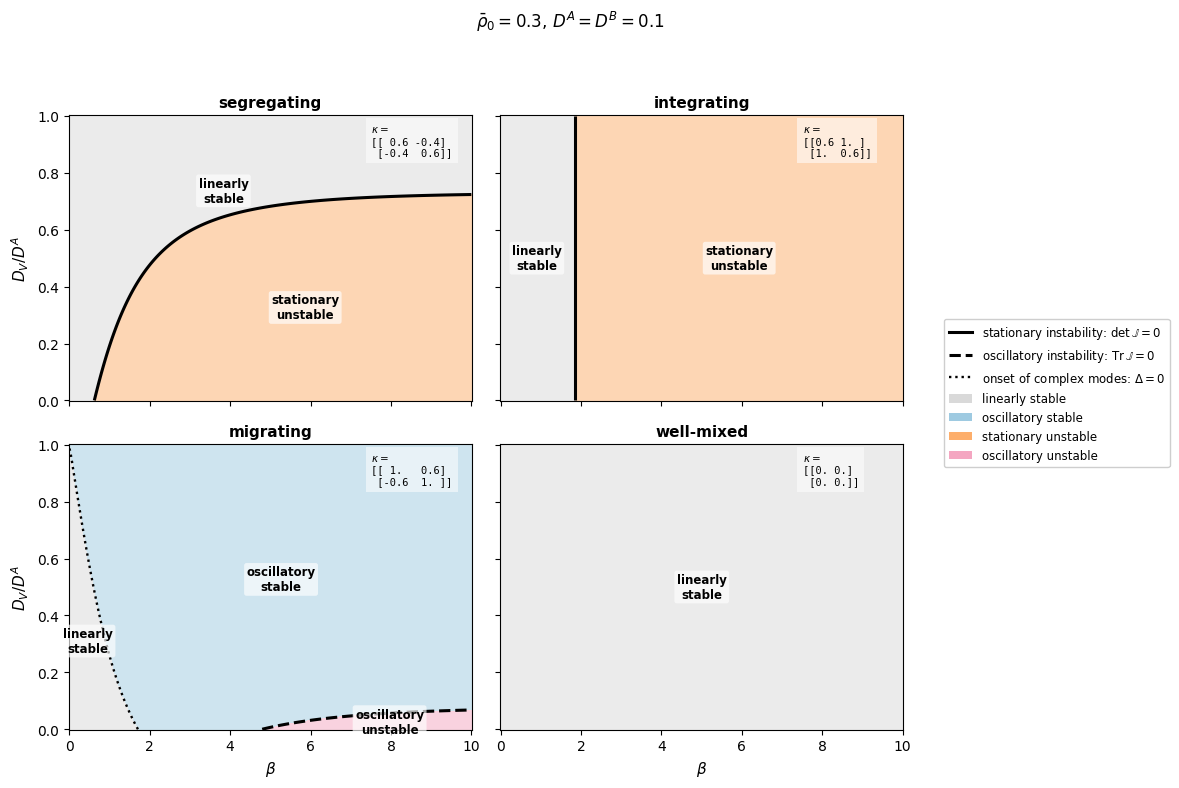

In [33]:
#!/usr/bin/env python3
"""
Tree-level critical surfaces of the Schelling--Voter hydrodynamic theory.

Default example:
    kappa(theta) = [[1-theta, theta],
                    [theta, 1-theta]]
    D_A = D_B = 1
    x axis: theta in [0,1]
    y axis: D_V / D_A
    several beta values shown as separate critical curves.

The script uses the exact microscopic response matrix Theta^{ab}(rho)
and the linear q^2 hydrodynamic matrix J.  The long-wavelength stability
boundary is r0 = min Re eig(J) = 0.  For the stationary Model-B branch one
may instead plot det(J)=0 subject to Tr(J)>0.

Dependencies: numpy, matplotlib.
"""
from matplotlib.lines import Line2D
from dataclasses import dataclass, replace
from math import factorial
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap, BoundaryNorm



# ============================================================================
# USER CONFIGURATION
# ============================================================================

REGIMES = {
    "segregating": np.array([
        [ 0.6, -0.4],
        [-0.4,  0.6],
    ]),
    "integrating": np.array([
        [0.6, 1.0],
        [1.0, 0.6],
    ]),
    "migrating": np.array([
        [ 1.0, 0.6],
        [-0.6, 1.0],
    ]),
    "well-mixed": np.array([
        [0.0, 0.0],
        [0.0, 0.0],
    ]),
}

# Scan beta against D_V / D_A
X_RANGE = (0.0, 10.0)
Y_RANGE = (0.0, 1.0)

NX = 301
NY = 301

# D_A = D_B = 1 fixes the time scale.
D_A = 0.1
D_B = 0.1

# Homogeneous background
RHO_0 = 0.30
RHO_A = 0.5 * (1.0 - RHO_0)
RHO_B = 0.5 * (1.0 - RHO_0)

# Either:
#   "r0"         -> full long-wavelength stability boundary
#   "stationary" -> det J = 0 with Tr J > 0
CRITERION = "stationary"

OUTPUT_FILE = "critical_surfaces_regimes_beta_Dv.pdf"
SHOW_FIGURE = True


# ======================================================================
# MODEL
# ======================================================================
@dataclass
class Params:
    D_A: float = 0.1
    D_B: float = 0.1
    D_V: float = 0.0
    beta: float = 1.0
    rho_A: float = 0.35
    rho_B: float = 0.35

    @property
    def rho_0(self):
        return 1.0 - self.rho_A - self.rho_B

    @property
    def Dv_ratio(self):
        return self.D_V / self.D_A
    


def kappa_from_theta(theta):
    """Requested reciprocal one-parameter interaction matrix."""
    return np.array([
        [theta, 1.0-theta],
        [1.0-theta, theta],
    ], dtype=float)


def multinomial3(n, i, j):
    k = n - i - j
    if min(i, j, k) < 0:
        return 0
    return factorial(n) // (factorial(i)*factorial(j)*factorial(k))


def theta_matrix(beta, kappa, rho_A, rho_B):
    r"""Exact finite-spectator response matrix Theta^{ab}(rho).

    Theta^{ab} = < tanh[beta/2 (kappa^{ab}+Delta)]
                   - tanh[beta/2 Delta] >,

    Delta=(m_A-n_A)kappa^{aA}+(m_B-n_B)kappa^{aB},
    with two destination-side and three source-side spectators.
    """
    rho_0 = 1.0 - rho_A - rho_B
    if rho_A < 0 or rho_B < 0 or rho_0 < 0:
        return np.full((2, 2), np.nan)

    T = np.zeros((2, 2), dtype=float)

    for mA in range(3):
        for mB in range(3-mA):
            m0 = 2-mA-mB
            pm = (multinomial3(2, mA, mB)
                  * rho_A**mA * rho_B**mB * rho_0**m0)

            for nA in range(4):
                for nB in range(4-nA):
                    n0 = 3-nA-nB
                    pn = (multinomial3(3, nA, nB)
                          * rho_A**nA * rho_B**nB * rho_0**n0)
                    weight = pm*pn
                    if weight == 0:
                        continue

                    for a in range(2):
                        delta = ((mA-nA)*kappa[a, 0]
                                 + (mB-nB)*kappa[a, 1])
                        t0 = np.tanh(0.5*beta*delta)
                        for b in range(2):
                            t1 = np.tanh(0.5*beta*(delta+kappa[a, b]))
                            T[a, b] += weight*(t1-t0)
    return T


@lru_cache(maxsize=None)
def cached_theta(beta, theta, rho_A, rho_B):
    """Cache Theta; useful when scanning D_V at fixed beta, theta and density."""
    return theta_matrix(beta, kappa_from_theta(theta), rho_A, rho_B)


def linear_matrix_J(p: Params, kappa: np.ndarray) -> np.ndarray:
    """Linear q^2 transport matrix J around the homogeneous state."""

    rho_A = p.rho_A
    rho_B = p.rho_B
    rho_0 = p.rho_0

    if rho_A < 0.0 or rho_B < 0.0 or rho_0 < -1e-14:
        return np.full((2, 2), np.nan)

    Theta = theta_matrix(
        beta=p.beta,
        kappa=kappa,
        rho_A=rho_A,
        rho_B=rho_B,
    )

    J = np.empty((2, 2), dtype=float)

    J[0, 0] = (
        p.D_A * (1.0 - rho_B)
        + p.D_V * rho_B
        - 10.0 * p.D_A * rho_0 * rho_A * Theta[0, 0]
    )

    J[0, 1] = (
        p.D_A * rho_A
        - p.D_V * rho_A
        - 10.0 * p.D_A * rho_0 * rho_A * Theta[0, 1]
    )

    J[1, 0] = (
        p.D_B * rho_B
        - p.D_V * rho_B
        - 10.0 * p.D_B * rho_0 * rho_B * Theta[1, 0]
    )

    J[1, 1] = (
        p.D_B * (1.0 - rho_A)
        + p.D_V * rho_A
        - 10.0 * p.D_B * rho_0 * rho_B * Theta[1, 1]
    )

    return J


def r0_value(p: Params, kappa: np.ndarray) -> float:
    J = linear_matrix_J(p, kappa)

    if not np.all(np.isfinite(J)):
        return np.nan

    eigvals = np.linalg.eigvals(J)

    return float(np.min(np.real(eigvals)))


def stationary_criterion(p: Params, kappa: np.ndarray) -> float:
    J = linear_matrix_J(p, kappa)

    if not np.all(np.isfinite(J)):
        return np.nan

    trJ = np.trace(J)

    # Only retain the stationary Model-B branch
    if trJ <= 0.0:
        return np.nan

    return float(np.linalg.det(J))


def critical_function(
    p: Params,
    kappa: np.ndarray,
    criterion: str,
) -> float:

    if criterion == "r0":
        return r0_value(p, kappa)

    if criterion == "stationary":
        return stationary_criterion(p, kappa)

    raise ValueError(f"Unknown criterion: {criterion}")


# ======================================================================
# PARAMETER SCANNING
# ======================================================================

def initial_params():
    DA = FIXED["D_A"]
    DB = FIXED["D_B"]
    if SYMMETRIC_BACKGROUND:
        r0 = FIXED["rho_0"]
        rA = rB = 0.5*(1-r0)
    else:
        rA = FIXED["rho_A"]
        rB = FIXED["rho_B"]

    return Params(
        D_A=DA,
        D_B=DB,
        D_V=FIXED["Dv_ratio"]*DA,
        beta=FIXED["beta"],
        theta=FIXED["theta"],
        rho_A=rA,
        rho_B=rB,
    )


def set_parameter(p, name, value):
    """Add new scan parameters here if needed."""
    if name == "theta":
        return replace(p, theta=value)
    if name == "beta":
        return replace(p, beta=value)
    if name == "D_A":
        return replace(p, D_A=value)
    if name == "D_B":
        return replace(p, D_B=value)
    if name == "D_V":
        return replace(p, D_V=value)
    if name == "Dv_ratio":
        return replace(p, D_V=value*p.D_A)
    if name == "rho_0":
        rA = rB = 0.5*(1-value)
        return replace(p, rho_A=rA, rho_B=rB)
    if name == "rho_A":
        return replace(p, rho_A=value)
    if name == "rho_B":
        return replace(p, rho_B=value)
    raise ValueError(f"Unsupported scan parameter: {name}")


def axis_label(name):
    labels = {
        "theta": r"$\theta$",
        "beta": r"$\beta$",
        "D_A": r"$D^A$",
        "D_B": r"$D^B$",
        "D_V": r"$D_V$",
        "Dv_ratio": r"$D_V/D^A$",
        "rho_0": r"$\rho_0^{(0)}$",
        "rho_A": r"$\rho_A^{(0)}$",
        "rho_B": r"$\rho_B^{(0)}$",
    }
    return labels.get(name, name)


def evaluate_grid(
    base: Params,
    kappa: np.ndarray,
    beta_values: np.ndarray,
    dv_values: np.ndarray,
):

    Z = np.full(
        (len(dv_values), len(beta_values)),
        np.nan,
        dtype=float,
    )

    for iy, dv_ratio in enumerate(dv_values):

        for ix, beta in enumerate(beta_values):

            p = replace(
                base,
                beta=float(beta),
                D_V=float(dv_ratio) * base.D_A,
            )

            Z[iy, ix] = critical_function(
                p,
                kappa,
                CRITERION,
            )

    return Z

def evaluate_stability_grid(
    base: Params,
    kappa: np.ndarray,
    beta_values: np.ndarray,
    dv_values: np.ndarray,
):
    """
    Evaluate the three relevant long-wavelength stability diagnostics:

        detJ          = det(J)
        trJ           = Tr(J)
        discriminant  = Tr(J)^2 - 4 det(J)

    Critical curves:
        detJ = 0, TrJ > 0       stationary / segregation instability
        trJ  = 0, detJ > 0      oscillatory / migration instability
        discriminant = 0        onset of complex eigenvalues
    """

    shape = (len(dv_values), len(beta_values))

    detJ = np.full(shape, np.nan)
    trJ = np.full(shape, np.nan)
    discr = np.full(shape, np.nan)

    # Masked quantities used specifically for drawing the two instability lines
    stationary = np.full(shape, np.nan)
    oscillatory = np.full(shape, np.nan)

    for iy, dv_ratio in enumerate(dv_values):

        for ix, beta in enumerate(beta_values):

            p = replace(
                base,
                beta=float(beta),
                D_V=float(dv_ratio) * base.D_A,
            )

            J = linear_matrix_J(p, kappa)

            if not np.all(np.isfinite(J)):
                continue

            tr = float(np.trace(J))
            det = float(np.linalg.det(J))
            disc = tr**2 - 4.0 * det

            trJ[iy, ix] = tr
            detJ[iy, ix] = det
            discr[iy, ix] = disc

            # Stationary Model-B-like instability:
            # one real eigenvalue passes through zero.
            if tr > 0.0:
                stationary[iy, ix] = det

            # Oscillatory instability:
            # complex conjugate pair crosses Re(lambda)=0.
            if det > 0.0:
                oscillatory[iy, ix] = tr

    return {
        "trace": trJ,
        "det": detJ,
        "discriminant": discr,
        "stationary": stationary,
        "oscillatory": oscillatory,
    }

    

# ======================================================================
# PLOT
# ======================================================================
def main():

    TOL = 1e-10

    # ============================================================
    # SETUP
    # ============================================================

    base = Params(
        D_A=D_A,
        D_B=D_B,
        D_V=0.0,
        beta=1.0,
        rho_A=RHO_A,
        rho_B=RHO_B,
    )

    betas = np.linspace(*X_RANGE, NX)
    dvs = np.linspace(*Y_RANGE, NY)

    BETA, DV = np.meshgrid(betas, dvs)

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(11.5, 8.0),
        sharex=True,
        sharey=True,
    )

    axes = axes.ravel()


    # ============================================================
    # COMMON PHASE COLORS
    # ============================================================

    phase_colors = [
        "#d9d9d9",   # stable, real
        "#9ecae1",   # stable, oscillatory
        "#fdae6b",   # stationary unstable
        "#f4a6c1",   # oscillatory unstable
    ]

    cmap = ListedColormap(phase_colors)

    norm = BoundaryNorm(
        [-0.5, 0.5, 1.5, 2.5, 3.5],
        cmap.N,
    )


    # ============================================================
    # HELPER: PLACE LABEL INSIDE A REGION
    # ============================================================

    def place_region_label(ax, mask, text, min_fraction=0.015):
        """
        Put text at an actual grid point inside the region.

        Very small regions are skipped so that labels do not clutter
        the plot.
        """

        iy, ix = np.where(mask)

        if len(ix) == 0:
            return

        # Skip tiny regions
        if len(ix) / mask.size < min_fraction:
            return

        beta_points = BETA[iy, ix]
        dv_points = DV[iy, ix]

        beta_c = np.mean(beta_points)
        dv_c = np.mean(dv_points)

        # Normalize distances because beta and Dv/D_A have
        # very different numerical ranges.
        dbeta = (
            (beta_points - beta_c)
            / (X_RANGE[1] - X_RANGE[0])
        )

        ddv = (
            (dv_points - dv_c)
            / (Y_RANGE[1] - Y_RANGE[0])
        )

        i_best = np.argmin(dbeta**2 + ddv**2)

        ax.text(
            beta_points[i_best],
            dv_points[i_best],
            text,
            ha="center",
            va="center",
            fontsize=8.5,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.20",
                facecolor="white",
                edgecolor="none",
                alpha=0.65,
            ),
            zorder=10,
        )


    # ============================================================
    # LOOP OVER THE FOUR REGIMES
    # ============================================================

    for ax, (regime, kappa) in zip(
        axes,
        REGIMES.items(),
    ):

        data = evaluate_stability_grid(
            base,
            kappa,
            betas,
            dvs,
        )

        tr = data["trace"]
        det = data["det"]
        disc = data["discriminant"]


        # --------------------------------------------------------
        # r0 = minimum real part of the two eigenvalues
        #
        # If disc >= 0:
        #
        #     lambda_- = (Tr J - sqrt(disc))/2
        #
        # If disc < 0:
        #
        #     Re lambda = Tr J / 2
        #
        # Treat tiny negative discriminants as zero.
        # --------------------------------------------------------

        disc_for_sqrt = np.maximum(disc, 0.0)

        r0 = np.where(
            disc >= -TOL,
            0.5 * (
                tr - np.sqrt(disc_for_sqrt)
            ),
            0.5 * tr,
        )


        # ========================================================
        # CLASSIFY FOUR REGIONS
        # ========================================================

        # (i) Linearly stable, purely relaxational
        stable_real = (
            (r0 > TOL)
            & (disc >= -TOL)
        )

        # (ii) Linearly stable, oscillatory
        stable_oscillatory = (
            (r0 > TOL)
            & (disc < -TOL)
        )

        # (iii) Stationary unstable:
        # real eigenvalues and at least one negative mode
        stationary_unstable = (
            (r0 < -TOL)
            & (disc >= -TOL)
        )

        # (iv) Oscillatory unstable:
        # complex pair with negative real part
        oscillatory_unstable = (
            (r0 < -TOL)
            & (disc < -TOL)
        )


        # ========================================================
        # BUILD PHASE MAP
        # ========================================================

        phase = np.full_like(
            tr,
            np.nan,
            dtype=float,
        )

        phase[stable_real] = 0
        phase[stable_oscillatory] = 1
        phase[stationary_unstable] = 2
        phase[oscillatory_unstable] = 3

        phase_masked = np.ma.masked_invalid(phase)


        # ========================================================
        # COLORED REGIONS
        # ========================================================

        ax.pcolormesh(
            BETA,
            DV,
            phase_masked,
            cmap=cmap,
            norm=norm,
            shading="auto",
            alpha=0.50,
            zorder=0,
        )


        # ========================================================
        # BOUNDARY 1:
        # stationary instability
        #
        # det J = 0, Tr J > 0
        # ========================================================

        det_stationary = np.where(
            tr > TOL,
            det,
            np.nan,
        )

        finite = det_stationary[
            np.isfinite(det_stationary)
        ]

        if (
            finite.size > 0
            and np.min(finite) < -TOL
            and np.max(finite) > TOL
        ):
            ax.contour(
                BETA,
                DV,
                det_stationary,
                levels=[0.0],
                colors="black",
                linewidths=2.2,
                linestyles="-",
                zorder=5,
            )


        # ========================================================
        # BOUNDARY 2:
        # oscillatory instability / Hopf boundary
        #
        # Tr J = 0, det J > 0, disc < 0
        # ========================================================

        trace_hopf = np.where(
            (det > TOL)
            & (disc < -TOL),
            tr,
            np.nan,
        )

        finite = trace_hopf[
            np.isfinite(trace_hopf)
        ]

        if (
            finite.size > 0
            and np.min(finite) < -TOL
            and np.max(finite) > TOL
        ):
            ax.contour(
                BETA,
                DV,
                trace_hopf,
                levels=[0.0],
                colors="black",
                linewidths=2.2,
                linestyles="--",
                zorder=5,
            )


        # ========================================================
        # BOUNDARY 3:
        # onset of complex eigenvalues
        #
        # Delta = (Tr J)^2 - 4 det J = 0
        # ========================================================

        finite = disc[
            np.isfinite(disc)
        ]

        if (
            finite.size > 0
            and np.min(finite) < -TOL
            and np.max(finite) > TOL
        ):
            ax.contour(
                BETA,
                DV,
                disc,
                levels=[0.0],
                colors="black",
                linewidths=1.7,
                linestyles=":",
                zorder=5,
            )


        # ========================================================
        # REGION LABELS
        # ========================================================

        place_region_label(
            ax,
            stable_real,
            "linearly\nstable",
        )

        place_region_label(
            ax,
            stable_oscillatory,
            "oscillatory\nstable",
        )

        place_region_label(
            ax,
            stationary_unstable,
            "stationary\nunstable",
        )

        place_region_label(
            ax,
            oscillatory_unstable,
            "oscillatory\nunstable",
        )


        # ========================================================
        # PANEL TITLE + KAPPA
        # ========================================================

        ax.set_title(
            regime,
            fontsize=11,
            fontweight="bold",
        )

        ax.text(
            0.75,
            0.97,
            r"$\kappa =$"
            + "\n"
            + str(kappa),
            transform=ax.transAxes,
            verticalalignment="top",
            horizontalalignment="left",
            fontsize=7.5,
            family="monospace",
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.55,
            ),
        )


        # ========================================================
        # DIAGNOSTICS
        # ========================================================

        print(
            regime,
            "r0 range:",
            np.nanmin(r0),
            np.nanmax(r0),
            "TrJ range:",
            np.nanmin(tr),
            np.nanmax(tr),
            "detJ range:",
            np.nanmin(det),
            np.nanmax(det),
            "disc range:",
            np.nanmin(disc),
            np.nanmax(disc),
        )


    # ============================================================
    # AXIS LABELS
    # ============================================================

    axes[2].set_xlabel(
        r"$\beta$",
        fontsize=11,
    )

    axes[3].set_xlabel(
        r"$\beta$",
        fontsize=11,
    )

    axes[0].set_ylabel(
        r"$D_V/D^A$",
        fontsize=11,
    )

    axes[2].set_ylabel(
        r"$D_V/D^A$",
        fontsize=11,
    )


    # ============================================================
    # SHARED LEGEND
    # ============================================================

    line_handles = [
        Line2D(
            [0], [0],
            color="black",
            linewidth=2.2,
            linestyle="-",
            label=r"stationary instability: "
                  r"$\det\mathbb{J}=0$",
        ),

        Line2D(
            [0], [0],
            color="black",
            linewidth=2.2,
            linestyle="--",
            label=r"oscillatory instability: "
                  r"$\mathrm{Tr}\,\mathbb{J}=0$",
        ),

        Line2D(
            [0], [0],
            color="black",
            linewidth=1.7,
            linestyle=":",
            label=r"onset of complex modes: "
                  r"$\Delta=0$",
        ),
    ]

    phase_handles = [
        Patch(
            facecolor=phase_colors[0],
            edgecolor="none",
            label="linearly stable",
        ),

        Patch(
            facecolor=phase_colors[1],
            edgecolor="none",
            label="oscillatory stable",
        ),

        Patch(
            facecolor=phase_colors[2],
            edgecolor="none",
            label="stationary unstable",
        ),

        Patch(
            facecolor=phase_colors[3],
            edgecolor="none",
            label="oscillatory unstable",
        ),
    ]

    fig.legend(
        handles=line_handles + phase_handles,
        loc="center left",
        bbox_to_anchor=(0.82, 0.50),
        fontsize=8.5,
        framealpha=0.95,
    )


    # ============================================================
    # FIGURE TITLE
    # ============================================================

    fig.suptitle(
        rf"$\bar\rho_0={base.rho_0:g}$, "
        rf"$D^A=D^B={base.D_A:g}$",
        fontsize=12,
    )


    # Leave room at the right for the shared legend
    fig.tight_layout(
        rect=[0.0, 0.0, 0.81, 0.94]
    )

    fig.savefig(
        OUTPUT_FILE,
        dpi=300,
        bbox_inches="tight",
    )

    print(f"Saved: {OUTPUT_FILE}")

    if SHOW_FIGURE:
        plt.show()


if __name__ == "__main__":
    main()


# Find the migrating regime again?

Saved: critical_beta_nonreciprocity.png
Trace range: -0.00681591380346646 0.13
det range: -0.0012249998515335547 0.002999999999999999
discriminant range: -0.00974581756865216 0.004900000000000005
r0 range: -0.03809048726833232 0.03258390864183207


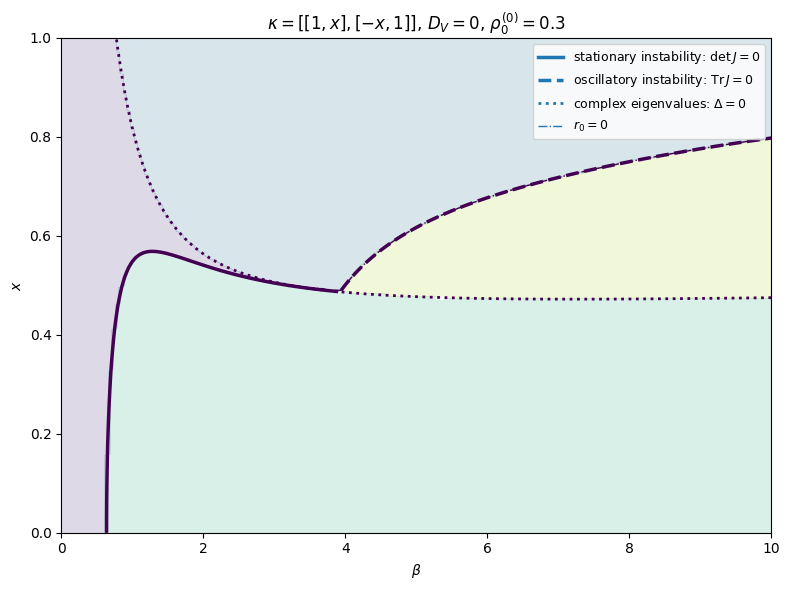

In [29]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


TOL = 1e-10

# Scan ranges
BETA_RANGE = (0.0, 10.0)
X_RANGE = (0.0, 1.0)

N_BETA = 201
N_X = 201

# Fixed parameters
D_A = 0.1
D_B = 0.1
D_V = 0.0

RHO_0 = 0.30
RHO_A = 0.5 * (1.0 - RHO_0)
RHO_B = 0.5 * (1.0 - RHO_0)

OUTPUT_FILE = "critical_beta_nonreciprocity.png"
SHOW_FIGURE = True


def kappa_from_x(x):
    """
    Non-reciprocal family

        kappa = [[ 1,  x],
                 [-x,  1]]
    """
    return np.array([
        [1.0,  x],
        [-x, 1.0],
    ])


def evaluate_beta_x_grid(base, betas, x_values):

    shape = (len(x_values), len(betas))

    trace = np.full(shape, np.nan)
    determinant = np.full(shape, np.nan)
    discriminant = np.full(shape, np.nan)
    r0 = np.full(shape, np.nan)

    for ix, x in enumerate(x_values):

        kappa = kappa_from_x(x)

        for ib, beta in enumerate(betas):

            p = replace(
                base,
                beta=float(beta),
                D_V=0.0,
            )

            J = linear_matrix_J(p, kappa)

            if not np.all(np.isfinite(J)):
                continue

            tr = float(np.trace(J))
            det = float(np.linalg.det(J))
            disc = tr**2 - 4.0 * det

            eig = np.linalg.eigvals(J)

            trace[ix, ib] = tr
            determinant[ix, ib] = det
            discriminant[ix, ib] = disc
            r0[ix, ib] = np.min(np.real(eig))

    return {
        "trace": trace,
        "det": determinant,
        "discriminant": discriminant,
        "r0": r0,
    }


def main():

    base = Params(
        D_A=D_A,
        D_B=D_B,
        D_V=0.0,
        beta=1.0,
        rho_A=RHO_A,
        rho_B=RHO_B,
    )

    betas = np.linspace(*BETA_RANGE, N_BETA)
    x_values = np.linspace(*X_RANGE, N_X)

    BETA, X = np.meshgrid(betas, x_values)

    data = evaluate_beta_x_grid(
        base,
        betas,
        x_values,
    )

    tr = data["trace"]
    det = data["det"]
    disc = data["discriminant"]
    r0 = data["r0"]


    # ============================================================
    # CLASSIFY THE FOUR REGIONS
    # ============================================================

    # 1. Stable, purely relaxational
    stable_real = (
        (tr > TOL)
        & (det > TOL)
        & (disc >= -TOL)
    )

    # 2. Stable, oscillatory
    stable_osc = (
        (tr > TOL)
        & (det > TOL)
        & (disc < -TOL)
    )

    # 3. Stationary instability
    #
    # For det < 0, the two eigenvalues are real and of opposite sign.
    stationary_unstable = (
        det < -TOL
    )

    # 4. Oscillatory instability
    #
    # Complex pair with negative real part.
    oscillatory_unstable = (
        (tr < -TOL)
        & (det > TOL)
        & (disc < -TOL)
    )


    # ============================================================
    # PLOT REGIONS
    # ============================================================

    fig, ax = plt.subplots(figsize=(8.0, 6.0))

    # Use integer phase labels:
    #
    # 0 = stable real
    # 1 = stable oscillatory
    # 2 = stationary unstable
    # 3 = oscillatory unstable

    phase = np.full_like(tr, np.nan)

    phase[stable_real] = 0
    phase[stable_osc] = 1
    phase[stationary_unstable] = 2
    phase[oscillatory_unstable] = 3

    # Light background shading for all four regions
    ax.contourf(
        BETA,
        X,
        phase,
        levels=[-0.5, 0.5, 1.5, 2.5, 3.5],
        alpha=0.18,
    )


    # ============================================================
    # BOUNDARY 1:
    # stationary instability
    #
    # det J = 0, Tr J > 0
    # ============================================================

    det_stationary = np.where(
        tr > TOL,
        det,
        np.nan,
    )

    if (
        np.nanmin(det_stationary) < -TOL
        and np.nanmax(det_stationary) > TOL
    ):
        ax.contour(
            BETA,
            X,
            det_stationary,
            levels=[0.0],
            linewidths=2.5,
            linestyles="-",
        )


    # ============================================================
    # BOUNDARY 2:
    # oscillatory instability
    #
    # Tr J = 0, det J > 0, disc < 0
    # ============================================================

    trace_hopf = np.where(
        (det > TOL) & (disc < -TOL),
        tr,
        np.nan,
    )

    if (
        np.any(np.isfinite(trace_hopf))
        and np.nanmin(trace_hopf) < -TOL
        and np.nanmax(trace_hopf) > TOL
    ):
        ax.contour(
            BETA,
            X,
            trace_hopf,
            levels=[0.0],
            linewidths=2.5,
            linestyles="--",
        )


    # ============================================================
    # BOUNDARY 3:
    # onset of complex eigenvalues
    #
    # discriminant = 0
    # ============================================================

    if (
        np.nanmin(disc) < -TOL
        and np.nanmax(disc) > TOL
    ):
        ax.contour(
            BETA,
            X,
            disc,
            levels=[0.0],
            linewidths=2.0,
            linestyles=":",
        )


    # ============================================================
    # OPTIONAL:
    # the complete r0 = 0 boundary
    #
    # This should coincide with either the stationary or Hopf
    # instability boundaries above.
    # ============================================================

    if (
        np.nanmin(r0) < -TOL
        and np.nanmax(r0) > TOL
    ):
        ax.contour(
            BETA,
            X,
            r0,
            levels=[0.0],
            linewidths=1.0,
            linestyles="-.",
        )


    # ============================================================
    # LEGEND
    # ============================================================

    line_legend = [
        Line2D(
            [0], [0],
            linewidth=2.5,
            linestyle="-",
            label=r"stationary instability: $\det J=0$",
        ),
        Line2D(
            [0], [0],
            linewidth=2.5,
            linestyle="--",
            label=r"oscillatory instability: $\mathrm{Tr}\,J=0$",
        ),
        Line2D(
            [0], [0],
            linewidth=2.0,
            linestyle=":",
            label=r"complex eigenvalues: $\Delta=0$",
        ),
        Line2D(
            [0], [0],
            linewidth=1.0,
            linestyle="-.",
            label=r"$r_0=0$",
        ),
    ]

    ax.legend(
        handles=line_legend,
        fontsize=9,
        loc="best",
    )


    # ============================================================
    # AXES
    # ============================================================

    ax.set_xlabel(r"$\beta$")
    ax.set_ylabel(r"$x$")

    ax.set_xlim(*BETA_RANGE)
    ax.set_ylim(*X_RANGE)

    ax.set_title(
        r"$\kappa=$"  + "$[[1,x],[-x,1]]$, "
        + rf"$D_V=0$, "
        + rf"$\rho_0^{{(0)}}={RHO_0:g}$"
    )

    fig.tight_layout()

    fig.savefig(
        OUTPUT_FILE,
        dpi=250,
        bbox_inches="tight",
    )

    print(f"Saved: {OUTPUT_FILE}")

    print(
        "Trace range:",
        np.nanmin(tr),
        np.nanmax(tr),
    )

    print(
        "det range:",
        np.nanmin(det),
        np.nanmax(det),
    )

    print(
        "discriminant range:",
        np.nanmin(disc),
        np.nanmax(disc),
    )

    print(
        "r0 range:",
        np.nanmin(r0),
        np.nanmax(r0),
    )

    if SHOW_FIGURE:
        plt.show()


if __name__ == "__main__":
    main()

Saved: critical_beta_nonreciprocity.png
Trace range: -0.00681591380346646 0.13
det range: -0.0012249985011619311 0.002999999999999999
discriminant range: -0.00974581756865216 0.004900000000000005
r0 range: -0.03809048726833232 0.03258390864183207


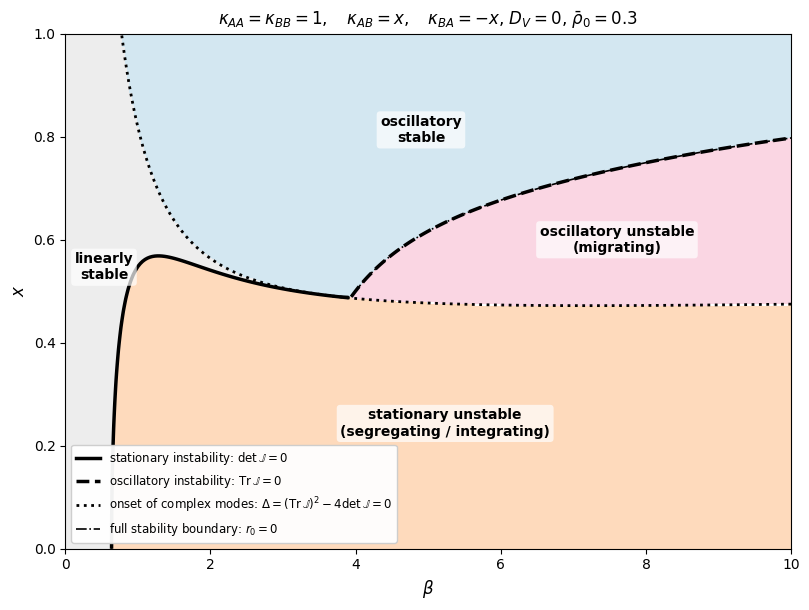

In [31]:
def main():

    from matplotlib.colors import ListedColormap, BoundaryNorm
    from matplotlib.lines import Line2D

    TOL = 1e-10

    # ------------------------------------------------------------------
    # Fixed parameters
    # ------------------------------------------------------------------

    base = Params(
        D_A=D_A,
        D_B=D_B,
        D_V=0.0,
        beta=1.0,
        rho_A=RHO_A,
        rho_B=RHO_B,
    )

    betas = np.linspace(*BETA_RANGE, N_BETA)
    x_values = np.linspace(*X_RANGE, N_X)

    BETA, X = np.meshgrid(betas, x_values)

    data = evaluate_beta_x_grid(
        base,
        betas,
        x_values,
    )

    tr = data["trace"]
    det = data["det"]
    disc = data["discriminant"]
    r0 = data["r0"]


    # ==================================================================
    # CLASSIFY THE FOUR REGIONS
    # ==================================================================

    # (i) Stable, real eigenvalues
    stable_real = (
        (tr > TOL)
        & (det > TOL)
        & (disc >= -TOL)
    )

    # (ii) Stable, complex eigenvalues
    stable_osc = (
        (tr > TOL)
        & (det > TOL)
        & (disc < -TOL)
    )

    # (iii) Stationary instability:
    # one real eigenvalue becomes negative
    stationary_unstable = (
        det < -TOL
    )

    # (iv) Oscillatory instability:
    # complex-conjugate pair with negative real part
    oscillatory_unstable = (
        (tr < -TOL)
        & (det > TOL)
        & (disc < -TOL)
    )


    # ==================================================================
    # PHASE MAP
    # ==================================================================

    phase = np.full_like(tr, np.nan)

    phase[stable_real] = 0
    phase[stable_osc] = 1
    phase[stationary_unstable] = 2
    phase[oscillatory_unstable] = 3

    phase_masked = np.ma.masked_invalid(phase)

    phase_colors = [
        "#d9d9d9",  # stable real
        "#9ecae1",  # stable oscillatory
        "#fdae6b",  # stationary unstable
        "#f4a6c1",  # oscillatory unstable
    ]

    cmap = ListedColormap(phase_colors)

    norm = BoundaryNorm(
        [-0.5, 0.5, 1.5, 2.5, 3.5],
        cmap.N,
    )


    # ==================================================================
    # FIGURE
    # ==================================================================

    fig, ax = plt.subplots(
        figsize=(8.2, 6.2)
    )

    ax.pcolormesh(
        BETA,
        X,
        phase_masked,
        cmap=cmap,
        norm=norm,
        shading="auto",
        alpha=0.45,
    )


    # ==================================================================
    # 1. STATIONARY INSTABILITY
    #
    # det J = 0, Tr J > 0
    # ==================================================================

    det_stationary = np.where(
        tr > TOL,
        det,
        np.nan,
    )

    if (
        np.any(np.isfinite(det_stationary))
        and np.nanmin(det_stationary) < -TOL
        and np.nanmax(det_stationary) > TOL
    ):
        ax.contour(
            BETA,
            X,
            det_stationary,
            levels=[0.0],
            linewidths=2.5,
            linestyles="-",
            colors="black",
        )


    # ==================================================================
    # 2. OSCILLATORY INSTABILITY / HOPF BOUNDARY
    #
    # Tr J = 0, det J > 0, Delta < 0
    # ==================================================================

    trace_hopf = np.where(
        (det > TOL) & (disc < -TOL),
        tr,
        np.nan,
    )

    if (
        np.any(np.isfinite(trace_hopf))
        and np.nanmin(trace_hopf) < -TOL
        and np.nanmax(trace_hopf) > TOL
    ):
        ax.contour(
            BETA,
            X,
            trace_hopf,
            levels=[0.0],
            linewidths=2.5,
            linestyles="--",
            colors="black",
        )


    # ==================================================================
    # 3. ONSET OF COMPLEX EIGENVALUES
    #
    # Delta = (Tr J)^2 - 4 det J = 0
    # ==================================================================

    if (
        np.nanmin(disc) < -TOL
        and np.nanmax(disc) > TOL
    ):
        ax.contour(
            BETA,
            X,
            disc,
            levels=[0.0],
            linewidths=2.0,
            linestyles=":",
            colors="black",
        )


    # ==================================================================
    # 4. COMPLETE r0 = 0 BOUNDARY
    #
    # This should coincide with the relevant portions of either
    # det J = 0 or Tr J = 0.
    # ==================================================================

    if (
        np.nanmin(r0) < -TOL
        and np.nanmax(r0) > TOL
    ):
        ax.contour(
            BETA,
            X,
            r0,
            levels=[0.0],
            linewidths=1.2,
            linestyles="-.",
            colors="black",
        )


    # ==================================================================
    # LABEL THE REGIONS DIRECTLY INSIDE THE PLOT
    # ==================================================================

    def place_region_label(mask, text):
        """
        Place a label at an actual grid point inside the specified region,
        chosen as the point closest to the region's centroid.
        """

        iy, ix = np.where(mask)

        if len(ix) == 0:
            return

        beta_points = BETA[iy, ix]
        x_points = X[iy, ix]

        # Geometric centroid
        beta_c = np.mean(beta_points)
        x_c = np.mean(x_points)

        # Pick the actual region point closest to that centroid.
        # Normalize by axis ranges so beta and x are weighted comparably.
        dbeta = (
            (beta_points - beta_c)
            / (BETA_RANGE[1] - BETA_RANGE[0])
        )

        dx = (
            (x_points - x_c)
            / (X_RANGE[1] - X_RANGE[0])
        )

        i_best = np.argmin(dbeta**2 + dx**2)

        ax.text(
            beta_points[i_best],
            x_points[i_best],
            text,
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.25",
                facecolor="white",
                edgecolor="none",
                alpha=0.70,
            ),
        )


    place_region_label(
        stable_real,
        "linearly\nstable",
    )

    place_region_label(
        stable_osc,
        "oscillatory\nstable",
    )

    place_region_label(
        stationary_unstable,
        "stationary unstable\n(segregating / integrating)",
    )

    place_region_label(
        oscillatory_unstable,
        "oscillatory unstable\n(migrating)",
    )


    # ==================================================================
    # LEGEND: ONLY EXPLAIN THE LINES
    # ==================================================================

    legend_elements = [
        Line2D(
            [0], [0],
            color="black",
            linewidth=2.5,
            linestyle="-",
            label=r"stationary instability: $\det\mathbb{J}=0$",
        ),
        Line2D(
            [0], [0],
            color="black",
            linewidth=2.5,
            linestyle="--",
            label=r"oscillatory instability: $\mathrm{Tr}\,\mathbb{J}=0$",
        ),
        Line2D(
            [0], [0],
            color="black",
            linewidth=2.0,
            linestyle=":",
            label=r"onset of complex modes: "
                  r"$\Delta=(\mathrm{Tr}\,\mathbb{J})^2"
                  r"-4\det\mathbb{J}=0$",
        ),
        Line2D(
            [0], [0],
            color="black",
            linewidth=1.2,
            linestyle="-.",
            label=r"full stability boundary: $r_0=0$",
        ),
    ]

    ax.legend(
        handles=legend_elements,
        fontsize=8.5,
        loc="best",
        framealpha=0.95,
    )


    # ==================================================================
    # AXES AND TITLE
    # ==================================================================

    ax.set_xlabel(
        r"$\beta$",
        fontsize=12,
    )

    ax.set_ylabel(
        r"$x$",
        fontsize=12,
    )

    ax.set_xlim(*BETA_RANGE)
    ax.set_ylim(*X_RANGE)

    ax.set_title(
        r"$\kappa_{AA}=\kappa_{BB}=1,\quad "
        r"\kappa_{AB}=x,\quad \kappa_{BA}=-x$"
        + rf", $D_V=0$, $\bar \rho_0 = {RHO_0:g}$"
    )

    fig.tight_layout()

    fig.savefig(
        OUTPUT_FILE,
        dpi=300,
        bbox_inches="tight",
    )

    print(f"Saved: {OUTPUT_FILE}")

    print(
        "Trace range:",
        np.nanmin(tr),
        np.nanmax(tr),
    )

    print(
        "det range:",
        np.nanmin(det),
        np.nanmax(det),
    )

    print(
        "discriminant range:",
        np.nanmin(disc),
        np.nanmax(disc),
    )

    print(
        "r0 range:",
        np.nanmin(r0),
        np.nanmax(r0),
    )

    if SHOW_FIGURE:
        plt.show()


BETA_RANGE = (0.0, 10.0)
X_RANGE = (0.0, 1.0)

N_BETA = 301
N_X = 301

# Fixed parameters
D_A = 0.1
D_B = 0.1
D_V = 0.0

RHO_0 = 0.30
RHO_A = 0.5 * (1.0 - RHO_0)
RHO_B = 0.5 * (1.0 - RHO_0)

OUTPUT_FILE = "critical_beta_nonreciprocity.png"
SHOW_FIGURE = True


main()